# **4. Feature Engineering Avanzado y Reducción de Dimensionalidad (t-SNE)**

> Esta guía teórico-práctica está estructurada con rigor matemático y analítico. Su propósito es **servir base conceptual para que los alumnos comprendan cómo los modelos "ven" e interactúan con el espacio multidimensional, y cómo la reducción de dimensionalidad preserva (o deforma) la topología de los datos.**



*Fig. 4.1. Una proyección no prueba por sí sola clases o grupos.*

## **4.1. El Espacio de Características y la Limitación de la Linealidad**

### 4.1.1. Transformación afín y dimensiones

Con muestras por filas, $X\in\mathbb{R}^{n\times d}$, una capa con $h$ salidas utiliza

$$O=XW+\mathbf{1}b^T,\qquad W\in\mathbb{R}^{d\times h},\quad b\in\mathbb{R}^h.$$

La convención de `nn.Linear` almacena los pesos como $(h,d)$ y calcula $XW^T+b$. No hay que mezclar ambas convenciones. Las $d$ características no tienen por qué ser independientes, y la regresión no busca una frontera de clases.



*Fig. 4.2. nn.Linear almacena W con forma h × d y utiliza su transpuesta.*

Una transformación afín combina una aplicación lineal y una traslación. Puede rotar, reflejar, escalar, cizallar, proyectar o colapsar dimensiones, según la matriz. Solo si la parte lineal es invertible conserva la estructura topológica global; una transformación afín no es necesariamente rígida.



*Fig. 4.3. Una transformación afín también puede reflejar o colapsar dimensiones.*

Cada puntuación afín tiene pendiente constante respecto de cada entrada, manteniendo las demás fijas. Esto no define una monotonía estricta global para un mapa vectorial. Un único hiperplano no separa dos anillos concéntricos con etiquetas opuestas; se necesita transformar atributos o utilizar un modelo no lineal. Una relación escalar en forma de U, como $(x-c)^2$, ilustra otra limitación sin recurrir a umbrales clínicos.



*Fig. 4.4. La monotonía de cada puntuación no equivale a monotonía de un mapa completo.*

### 4.1.2. Activaciones y capacidad de representación

Las activaciones intermedias impiden que toda la red se reduzca a una única transformación afín. Permiten modelar fronteras no lineales, sin garantizar que los datos se vuelvan separables ni que el entrenamiento encuentre una solución adecuada.



*Fig. 4.5. No toda transformación vuelve separables todos los datos.*



*Fig. 4.6. Apilar solo aplicaciones afines produce otra aplicación afín.*

Apilar capas afines sin activaciones produce otra capa afín:

$$ (XW_1+b_1)W_2+b_2=X(W_1W_2)+(b_1W_2+b_2).$$

Una capa estrecha puede limitar el rango de la matriz equivalente. La no linealidad debe aparecer entre transformaciones para ampliar la familia de funciones representables.

**ReLU:** $\operatorname{ReLU}(x)=\max(0,x)$. Es continua y lineal a trozos, con gradiente cero para valores negativos y no diferenciable en cero. La interpretación como plegado es una analogía; matemáticamente también puede colapsar regiones y perder información.



*Fig. 4.7. ReLU puede colapsar regiones; el plegado es una analogía.*

**Sigmoide:** $1/(1+e^{-x})$, con rango $(0,1)$. **Tanh:** $(e^x-e^{-x})/(e^x+e^{-x})$, con rango $(-1,1)$. Ambas son suaves y saturan lejos del origen. La simetría de tanh no garantiza una media nula para cualquier distribución de entrada.



*Fig. 4.8. La simetría de tanh no garantiza media nula en cualquier distribución.*

#### Comparación

| Operación | Geometría | Alcance |
|---|---|---|
| Afín | Incluye rotación, escala, cizalla, reflexión y traslación | Puntuaciones afines y fronteras lineales por pares. |
| Afines apiladas | Una aplicación afín equivalente, posiblemente con rango restringido | No añade no linealidad. |
| ReLU entre capas | Transformación lineal a trozos | Permite fronteras complejas; no asegura separabilidad. |
| Sigmoide o tanh entre capas | Transformación suave y no lineal | Aumenta capacidad; puede sufrir saturación. |



*Fig. 4.9. La capacidad de representar no garantiza el resultado del entrenamiento.*

## **4.2. El Teorema de Cover y el Truco del Kernel**

### 4.2.1. Alcance del teorema de Cover

El resultado de Cover relaciona la separabilidad de dicotomías de puntos en posición general con la dimensión del espacio. Motiva transformaciones no lineales a espacios de mayor dimensión. No garantiza que cualquier mapeo separe cualquier dataset, ni que aumentar la dimensión mejore la generalización. La regularización y la elección del mapeo siguen siendo esenciales.

Un mapeo $\Phi:\mathbb{R}^d\to\mathcal{H}$ puede introducir características no lineales. Por ejemplo, $\Phi(x)=(x,x^2)$ permite separar con una recta ciertos patrones que no se separan en la entrada unidimensional.

Un espacio de Hilbert es un espacio con producto interno y completo; puede tener dimensión finita o infinita. En dimensión infinita no se expresa la dimensión de un hiperplano como un entero «$\mathcal{H}-1$». No toda proyección ni todo dataset cumplen las condiciones de separabilidad.



*Fig. 4.10. Cover motiva la expansión bajo condiciones; no promete generalización.*

### 4.2.2. Costo explícito y kernel trick

Construir todas las coordenadas de una expansión de características puede ser costoso o imposible si es infinita. La maldición de la dimensionalidad es más amplia: incluye dispersión del muestreo, concentración de distancias y necesidades estadísticas, según la distribución y la métrica. No equivale simplemente a quedarse sin memoria.



*Fig. 4.11. La maldición de la dimensionalidad no equivale solo a uso de memoria.*

El dual del SVM utiliza productos internos:

$$\max_\alpha\sum_i\alpha_i-\frac12\sum_{i,j}\alpha_i\alpha_j y_i y_j\langle x_i,x_j\rangle,$$

con $\sum_i\alpha_i y_i=0$ y $0\leq\alpha_i\leq C$ para margen suave. Esto permite sustituir el producto interno por un kernel válido.



*Fig. 4.12. La matriz de Gram de un kernel válido es semidefinida positiva.*

$$K(x_i,x_j)=\langle\Phi(x_i),\Phi(x_j)\rangle_{\mathcal H}.$$

El kernel trick calcula ese valor sin formar explícitamente $\Phi$. Un kernel debe inducir matrices de Gram semidefinidas positivas; no cualquier similitud sirve. El ahorro depende de la función elegida y no es «infinitamente menor». Una matriz densa de kernels para $n$ muestras aún ocupa $O(n^2)$ memoria.



*Fig. 4.13. El costo aún depende de muestras, kernel y vectores de soporte.*

## **4.3. Reducción de Dimensionalidad No Lineal: El Algoritmo t-SNE**

### 4.3.1. PCA y variedades curvas

PCA encuentra un subespacio lineal que retiene varianza, sin requerir que todos los datos sigan una estructura intrínsecamente lineal. Puede perder vecindades de una variedad curva al proyectarla a pocas dimensiones. t-SNE optimiza otro objetivo: afinidades entre pares, priorizando estructura local. Ninguno garantiza conservar toda la topología o separar clases.



*Fig. 4.14. Una proyección lineal puede superponer regiones de una variedad curva.*



*Fig. 4.15. Ninguno garantiza conservar toda la topología.*

### **4.3.2. Formulación Matemática de t-SNE (Stochastic Neighbor Embedding)**

El objetivo de t-SNE es **mapear un conjunto de puntos de alta dimensión $\mathbf{x}_1, \dots, \mathbf{x}_n$ a un conjunto de puntos correspondientes de baja dimensión $\mathbf{y}_1, \dots, \mathbf{y}_n$** (típicamente en el plano $\mathbb{R}^2$ para visualización) **de forma que se preserven al máximo las relaciones de vecindad local**.



*Fig. 4.16. La optimización se realiza sobre las coordenadas del embedding.*

#### **Paso 1: Probabilidades en Alta Dimensión (Espacio de Entrada)**

> t-SNE **convierte las distancias euclidianas entre los puntos en probabilidades condicionales que representan la similitud.**

Para $j\neq i$,

$$p_{j|i}=\frac{\exp(-\|x_i-x_j\|^2/(2\sigma_i^2))}{\sum_{k\neq i}\exp(-\|x_i-x_k\|^2/(2\sigma_i^2))},\qquad p_{i|i}=0.$$

$\sigma_i$ es la **desviación estándar o ancho de banda**; la varianza es $\sigma_i^2$. Estas probabilidades están normalizadas por fila. En la formulación exacta, todos los pares a distancia finita tienen peso positivo, aunque algunos sean numéricamente muy pequeños; las aproximaciones pueden truncar vecinos.



*Fig. 4.17. El ancho σᵢ se adapta por fila; σᵢ² es la varianza.*



*Fig. 4.18. La probabilidad del propio punto se fija en cero.*

Este valor **se determina de forma adaptativa para cada punto mediante el concepto de Perplejidad** (*Perplexity*), especificado por el usuario:

$$\operatorname{Perp}(P_i) = 2^{H(P_i)}$$

Donde $H(P_i)$ es la **entropía de Shannon de la distribución de probabilidad condicional:**

$$H(P_i) = -\sum_{j} p_{j \mid i} \log_2 p_{j \mid i}$$



*Fig. 4.19. Perplejidad no es el número exacto de enlaces de peso no nulo.*

---

#### **Paso 1.1. La Perplejidad: Mecánica, Matemática y Geometría**

La **Perplejidad** es el hiperparámetro fundamental de t-SNE. **Controla de manera indirecta el radio de vecindad $\sigma_i$ para cada punto individual según la densidad de su entorno.**

---

##### 1. Entropía y perplejidad

$$H(P_i)=-\sum_{j\neq i}p_{j|i}\log_2p_{j|i},\qquad\operatorname{Perp}(P_i)=2^{H(P_i)}.$$

Una distribución uniforme sobre $k$ resultados tiene perplejidad $k$. Esto da la idea de «número efectivo de vecinos», sin imponer exactamente $k$ enlaces no nulos.



*Fig. 4.20. Una distribución uniforme sobre k elementos tiene perplejidad k.*

##### 2. Vecindad efectiva

Perplejidad 30 pide una entropía equivalente a 30 vecinos equiprobables. No significa conservar solo 30 vecinos ni dar peso cero al resto. Su valor debe ser menor que el número de muestras en la implementación de scikit-learn.

##### 3. Calibrar el ancho de banda

Se busca por fila una escala que aproxime la entropía objetivo. Si la distribución es demasiado difusa, se reduce el ancho; si está demasiado concentrada, se aumenta. La implementación suele buscar sobre la precisión inversa proporcional a $1/\sigma_i^2$, con límites de iteración y tolerancia sobre la entropía. Empates de distancias pueden impedir alcanzar ciertas entropías exactamente. Una zona dispersa suele necesitar una escala mayor que una densa para una vecindad efectiva comparable.



*Fig. 4.21. La búsqueda de ancho de banda aproxima una entropía objetivo.*

Las probabilidades conjuntas simétricas son

$$p_{ij}=\frac{p_{j|i}+p_{i|j}}{2n},\qquad p_{ii}=0.$$

Así, $p_{ij}=p_{ji}$ y $\sum_{i\neq j}p_{ij}=1$. La simetrización ayuda a que un punto tenga afinidades relevantes incluso si pocos otros puntos lo seleccionan como vecino; no hace que todos los pares contribuyan con igual peso ni elimina todos los efectos de valores atípicos.



*Fig. 4.22. La simetría no asigna el mismo peso a todos los pares.*

##### 4. Densidades y tamaños aparentes

La escala adaptativa puede expandir regiones densas y contraer regiones dispersas en la visualización. Los tamaños y densidades de las islas no reproducen necesariamente los originales. No se garantiza que todos los grupos queden con igual tamaño o densidad.



*Fig. 4.23. Las áreas y densidades de islas no son estimaciones fieles de las originales.*

#### **Paso 2. La Geometría de Proyección y el Problema de Hacinamiento**



*Fig. 4.24. Reducir dimensión fuerza compromisos entre relaciones de distancia.*

##### 1. Hacinamiento

El volumen de una bola de dimensión $D$ es

$$V_D(r)=\frac{\pi^{D/2}}{\Gamma(D/2+1)}r^D.$$

En una misma dimensión, $V_D(2r)/V_D(r)=2^D$: una capa exterior puede contener mucho más volumen que una interior. Esto ayuda a entender por qué muchas relaciones de distancia no pueden acomodarse fielmente al bajar a dos dimensiones. No significa que el volumen de una bola de radio fijo crezca siempre con $D$, ni que todos los datos colapsen necesariamente en el centro.



*Fig. 4.25. El volumen a radio fijo no tiene por qué crecer con la dimensión.*

##### 2. Afinidades con colas pesadas

t-SNE usa, en su formulación bidimensional habitual,

$$q_{ij}=\frac{(1+\|y_i-y_j\|^2)^{-1}}{\sum_{k\neq l}(1+\|y_k-y_l\|^2)^{-1}},\qquad q_{ii}=0.$$

El núcleo tiene la forma de una t de Student con un grado de libertad. $q$ es una distribución normalizada sobre pares; no es simplemente una densidad unidimensional de Cauchy evaluada sin normalización.



*Fig. 4.26. Núcleos sin normalizar; la cola de Student decae más lentamente.*

##### 3. Por qué importan las colas

El núcleo gaussiano decrece exponencialmente con la distancia al cuadrado; el de t-SNE tiene una cola proporcional a $d^{-2}$. Eso permite representar afinidades moderadas con separaciones mayores en el mapa y alivia el hacinamiento. No garantiza islas limpias, clases homogéneas ni preservación de distancias globales.



*Fig. 4.27. Permiten representar afinidades moderadas con separaciones mayores.*

### 4.3.3. Divergencia KL

$$\mathcal L=\operatorname{KL}(P\|Q)=\sum_{i\neq j}p_{ij}\log\frac{p_{ij}}{q_{ij}}.$$

La suma compara dos distribuciones normalizadas sobre pares. El objetivo no es convexo en las coordenadas; pueden obtenerse distintos mapas con diferentes inicializaciones y parámetros.



*Fig. 4.28. Cambiar la perplejidad modifica el objetivo P.*

Si un par tiene $p_{ij}$ alto y $q_{ij}$ pequeño, contribuye mucho a la pérdida. Esto favorece preservar vecinos. Para un par con $p_{ij}$ pequeño, su término directo tiene poco peso, pero **t-SNE sí incluye repulsión global** a través de la normalización de $Q$. No se puede concluir que ignore completamente los pares lejanos.

#### 4.3.3.1. Gradiente de las coordenadas

$$\frac{\partial\mathcal L}{\partial y_i}=4\sum_{j\neq i}(p_{ij}-q_{ij})(y_i-y_j)(1+\|y_i-y_j\|^2)^{-1}.$$

La actualización de descenso usa el **negativo** de este gradiente. De ahí se obtiene la interpretación de atracción y repulsión.

##### Atracción y repulsión

En la dirección de descenso, el término con $p_{ij}$ atrae pares afines y el término con $q_{ij}$ los repele. La formulación exacta incluye todos los pares; implementaciones aproximadas aceleran las afinidades y las fuerzas lejanas. La analogía física ayuda a interpretar la actualización, pero no implica fuerzas físicas constantes ni garantías de estabilidad numérica.



*Fig. 4.29. t-SNE sí tiene repulsión entre puntos en la formulación exacta.*

### 4.3.4. Interpretar el mapa con cuidado

| Observación en 2D | Interpretación válida |
|---|---|
| Islas de tamaño parecido | No prueba tamaños o densidades originales iguales. |
| Dos islas muy separadas | No permite convertir directamente esa separación en una distancia original. |
| Muchos grupos pequeños | Pueden cambiar al variar perplejidad, semilla o preprocesamiento. |
| Anillos o relaciones de inclusión | No están garantizados aunque existan en alta dimensión. |
| Colores de clase separados | Las etiquetas se usan aquí para colorear, no para entrenar t-SNE. |

Conviene repetir con varios parámetros y contrastar las vecindades en la entrada. Un mapa atractivo no demuestra la existencia de clusters ni evalúa por sí solo un clasificador.



*Fig. 4.30. Distancias entre islas y relaciones de inclusión no están garantizadas.*



*Fig. 4.31. La perplejidad 30 es un punto de partida, no un óptimo universal.*



*Fig. 4.32. Las etiquetas se reservan para colorear los resultados.*

## **4.4. Implementación con PyTorch**

### **CELDA 1: Instalación de Dependencias y Configuración del Entorno**

In [1]:
# ==============================================================================
# CELDA 1: Configuración de Dependencias, Hardware y Semillas de Reproducibilidad
# ==============================================================================

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

def set_deterministic_seed(seed_value: int = 42) -> None:
    """
    Establece las semillas pseudoaleatorias en Python, NumPy y PyTorch para
    facilitar la repetición dentro del mismo entorno.

    Args:
        seed_value (int): Valor numérico entero de la semilla.
    """
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed_value)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_deterministic_seed(42)
execution_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"[INFO] Entorno listo. Dispositivo de cómputo en PyTorch: {execution_device}")

[INFO] Entorno listo. Dispositivo de cómputo en PyTorch: cpu


Fijar semillas ayuda a reproducir una ejecución. En CPU también puede haber paralelismo y operaciones no deterministas. `cudnn.benchmark=False` evita la selección por mediciones de rendimiento; `cudnn.deterministic=True` restringe los algoritmos de convolución cubiertos por esa opción. No garantiza determinismo de todas las operaciones CUDA. `torch.use_deterministic_algorithms(True)` ofrece un control adicional y puede lanzar errores si no hay alternativa determinista. No se promete igualdad bit a bit entre versiones o plataformas.

### Celda 2. Datos de dígitos

`load_digits()` contiene 1.797 imágenes de 8 × 8, con 64 características por muestra. El Dataset guarda los tensores; el DataLoader entrega lotes alineados de datos y etiquetas.

In [2]:
# ==============================================================================
# CELDA 2: Pipeline de Datos en PyTorch para Imágenes de Dígitos (64 Dimensiones)
# ==============================================================================

class DigitsTensorDataset(Dataset):
    """
    Dataset personalizado en PyTorch para almacenar y gestionar el dataset Digits
    (imágenes de 8x8 píxeles aplanadas en vectores de 64 dimensiones continuas).

    Atributos:
        features_tensor (torch.Tensor): Tensor continuo de forma (N, 64) normalizado [0, 1].
        labels_tensor (torch.Tensor): Tensor discreto de forma (N,) con las clases (0 al 9).
    """
    def __init__(self):
        """
        Carga el conjunto de datos 'Digits' de Scikit-Learn y lo transforma
        en tensores de PyTorch con normalización Min-Max.
        """
        raw_digits = load_digits()
        raw_features = raw_digits.data.astype(np.float32)
        raw_labels = raw_digits.target.astype(np.int64)

        # Normalización de los píxeles a la escala [0.0, 1.0]
        normalized_features = raw_features / 16.0

        self.features_tensor = torch.tensor(normalized_features, dtype=torch.float32)
        self.labels_tensor = torch.tensor(raw_labels, dtype=torch.long)
        self.images_matrix = raw_digits.images

    def __len__(self) -> int:
        """
        Retorna la cantidad total de muestras contenidas en el dataset.
        """
        return len(self.features_tensor)

    def __getitem__(self, sample_index: int):
        """
        Recupera una muestra individual del dataset según su índice.

        Args:
            sample_index (int): Índice de la muestra a recuperar.

        Returns:
            tuple: (features_sample, label_sample) como tensores de PyTorch.
        """
        return self.features_tensor[sample_index], self.labels_tensor[sample_index]

# Instanciación del Dataset y DataLoader de PyTorch
digits_dataset = DigitsTensorDataset()
digits_dataloader = DataLoader(
    digits_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)



print(f"[INFO] Dataset cargado: {len(digits_dataset)} muestras con {digits_dataset.features_tensor.shape[1]} características (dimensiones).")

[INFO] Dataset cargado: 1797 muestras con 64 características (dimensiones).


#### A. Interfaz de Dataset

Para este Dataset de acceso por índice implementamos `__getitem__` y `__len__`. Heredar de `Dataset` es el patrón habitual, aunque el protocolo también puede satisfacerse mediante otros objetos. Existen además datasets iterables con una interfaz distinta.

#### B. Representación y escala

Los píxeles toman valores entre 0 y 16; dividir por 16 utiliza una escala conocida común para todas las columnas. No convierte los valores discretos en observaciones continuas nuevas. `float32` es adecuado para los atributos; `long` representa las clases. No todo algoritmo de clasificación exige etiquetas `int64`, aunque es el tipo habitual para objetivos de `CrossEntropyLoss` en PyTorch. El escalado por atributo puede alterar vecinos; el escalado global uniforme suele compensarse en los anchos de banda de t-SNE.

#### **C. Métodos Especiales `__len__` y `__getitem__`**

```python
def __len__(self) -> int:
    return len(self.features_tensor)

def __getitem__(self, sample_index: int):
    return self.features_tensor[sample_index], self.labels_tensor[sample_index]
```

* **`__len__`:** Retorna la cantidad total de muestras en el conjunto ($1.797$). **Es invocado internamente por el `DataLoader` y por los `Samplers` para conocer los límites de indexación.**


* **`__getitem__`:** Define la regla de acceso aleatorio $O(1)$. **Dado un índice `sample_index`, retorna una tupla con la muestra y su etiqueta correspondiente `(features_sample, label_sample)` en formato de tensores individuales.**

---

#### **D. Configuración del `DataLoader`**

```python
digits_dataloader = DataLoader(
    digits_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)
```

* **`batch_size=256`:** Agrupa las muestras individuales en bloques de 256 elementos. **En la última iteración, procesará el remanente ($1797 \pmod{256} = 5$ muestras).**


* **`shuffle=False`:** **Mantiene el orden original y determinista de los datos**. Esto es crítico para **garantizar que, al concatenar y comparar las etiquetas con las proyecciones 2D de t-SNE, exista una correspondencia unívoca e inalterada fila por fila.**


* **`num_workers=0`:** La carga de datos se ejecuta en el proceso principal de Python. **Resulta adecuado para conjuntos tabulares pequeños que caben por completo en la memoria RAM.**

### Celda 3. Consolidar lotes

En este ejemplo no se entrena una red: PyTorch organiza los datos y los convierte a NumPy para scikit-learn. Por ello mantenemos los lotes en CPU, evitando una transferencia a GPU y de vuelta que no aportaría cómputo útil.

In [3]:
# No hay una red neuronal en este paso: conservar CPU evita copias innecesarias.
def extract_features_from_loader(data_loader: DataLoader):
    features, labels = [], []
    for batch_features, batch_labels in data_loader:
        features.append(batch_features)
        labels.append(batch_labels)
    return torch.cat(features, dim=0).numpy(), torch.cat(labels, dim=0).numpy()

features_matrix, labels_vector = extract_features_from_loader(digits_dataloader)
print(f"Matriz: {features_matrix.shape}; etiquetas: {labels_vector.shape}")


Matriz: (1797, 64); etiquetas: (1797,)


#### A. Dispositivo y transferencias

Una red real podría calcular embeddings en GPU y devolverlos a CPU para un método que los requiera allí. `.to(device)` no garantiza por sí sola una copia asíncrona; esta depende de `non_blocking`, memoria fijada y hardware. Aquí se concatenan directamente los lotes de CPU.

#### B. Concatenar filas

`torch.cat(..., dim=0)` produce una matriz $(1797,64)$ y un vector de etiquetas $(1797,)$. Hay ocho lotes: siete de 256 y uno de 5. `stack` exige formas iguales y añade un eje, por lo que no apila directamente esa lista desigual. `.numpy()` expone los datos CPU cuando se cumplen sus requisitos; scikit-learn también acepta otras entradas convertibles a arreglos.

### Celda 4. Variar la perplejidad

Se ajusta un mapa distinto para cada valor de `[2, 10, 30, 50, 100]`, conservando su embedding y KL final. Los números de la ejecución se registran, no se fijan como resultados universales. Las etiquetas no participan en el ajuste.

In [4]:
# ==============================================================================
# CELDA 4: Ejecución de t-SNE evaluando múltiples niveles de Perplejidad
# ==============================================================================

def run_tsne_grid_search(
    high_dim_data: np.ndarray,
    perplexity_list: list,
    random_state: int = 42,
    max_iterations: int = 1000
) -> dict:
    """
    Ejecuta el algoritmo t-SNE para diferentes valores de perplejidad y registra
    las coordenadas 2D obtenidas junto con la divergencia KL final calculada.

    Args:
        high_dim_data (np.ndarray): Matriz de datos de entrada en alta dimensión (N, D).
        perplexity_list (list): Lista con los valores de perplejidad a evaluar.
        random_state (int): Semilla para facilitar la repetición de la optimización.
        max_iterations (int): Número máximo de iteraciones de descenso de gradiente.

    Returns:
        dict: Diccionario que almacena las coordenadas 2D y el costo KL por cada perplejidad.
    """
    experiment_results = {}

    for perplexity_value in perplexity_list:
        print(f"[INFO] Optimizando t-SNE con Perplejidad = {perplexity_value}...")
        tsne_model = TSNE(
            n_components=2,
            perplexity=perplexity_value,
            max_iter=max_iterations,
            init="pca",
            learning_rate="auto",
            random_state=random_state
        )

        low_dim_embedding = tsne_model.fit_transform(high_dim_data)

        experiment_results[perplexity_value] = {
            "embedding": low_dim_embedding,
            "kl_divergence": tsne_model.kl_divergence_
        }

    return experiment_results

# Rango amplio de perplejidades para explorar la topología
perplexity_candidates = [2, 10, 30, 50, 100]
tsne_results = run_tsne_grid_search(features_matrix, perplexity_candidates)
print("[INFO] Todos los embeddings de t-SNE han sido calculados con éxito.")

[INFO] Optimizando t-SNE con Perplejidad = 2...
[INFO] Optimizando t-SNE con Perplejidad = 10...
[INFO] Optimizando t-SNE con Perplejidad = 30...
[INFO] Optimizando t-SNE con Perplejidad = 50...
[INFO] Optimizando t-SNE con Perplejidad = 100...
[INFO] Todos los embeddings de t-SNE han sido calculados con éxito.


#### A. Parámetros de TSNE

Usamos `max_iter`, nombre actual del parámetro de iteraciones de scikit-learn, en lugar del antiguo `n_iter`. `init="pca"` suele dar un inicio más estable que el aleatorio; no garantiza un óptimo global.

La opción `learning_rate="auto"` utiliza

$$\eta=\max\left(\frac{N}{4\,\text{early_exaggeration}},50\right).$$

En el caso usado, `early_exaggeration=12` modifica las afinidades durante las primeras 250 iteraciones. El algoritmo Barnes–Hut aproxima las fuerzas lejanas; su costo habitual por iteración es $O(N\log N)$, frente al $O(N^2)$ del método exacto. La construcción de vecinos también tiene un costo dependiente de los datos y la métrica.

#### B. Ajuste y costo final

`fit_transform` devuelve $(N,2)$. `kl_divergence_` informa el costo final de esa ejecución. Para **la misma matriz $P$** y configuración de evaluación, un costo menor indica mejor ajuste al objetivo. Cambiar la perplejidad cambia $P$, por lo que no se deben ordenar las visualizaciones por sus valores KL como si midieran el mismo problema.

#### C. Explorar varios valores

Una perplejidad baja enfatiza escalas muy locales y puede fragmentar estructuras; una alta considera entornos más amplios y puede ocultar detalle. Ningún valor, incluido 30, es óptimo para todos los datos. Hay que comparar varias semillas y escalas con el objetivo analítico del estudio.

### Celda 5. PCA y t-SNE

Se grafican las mismas muestras con dos objetivos diferentes. PCA conserva varianza lineal; t-SNE ajusta afinidades. El mapa con perplejidad 30 es un ejemplo elegido para comparar, no un resultado declarado óptimo.

In [5]:
# ==============================================================================
# CELDA 5: Tablero Interactivo con Plotly: Proyección Lineal (PCA) vs. No Lineal (t-SNE)
# ==============================================================================

# 1. Proyección de referencia con PCA (Lineal)
pca_model = PCA(n_components=2, random_state=42)
pca_embedding = pca_model.fit_transform(features_matrix)

# 2. Embedding t-SNE elegido para comparar (Perplejidad = 30)
selected_tsne_embedding = tsne_results[30]["embedding"]

# 3. Creación del DataFrame para Plotly
comparison_df = pd.DataFrame({
    "PCA_1": pca_embedding[:, 0],
    "PCA_2": pca_embedding[:, 1],
    "tSNE_1": selected_tsne_embedding[:, 0],
    "tSNE_2": selected_tsne_embedding[:, 1],
    "Digit": [f"Dígito {digit_label}" for digit_label in labels_vector],
    "Label_Code": labels_vector
})

# 4. Construcción de Subplots Interactivos con Plotly
dashboard_figure = make_subplots(
    rows=1, cols=2,
    subplot_titles=(
        "<b>PCA: varianza lineal</b>",
        "<b>t-SNE: afinidades locales, Perp=30</b>"
    ),
    horizontal_spacing=0.08
)

# Mapa de colores para los 10 dígitos
palette_colors = px.colors.qualitative.Bold

for digit_idx in range(10):
    digit_subset = comparison_df[comparison_df["Label_Code"] == digit_idx]

    # Traza PCA
    dashboard_figure.add_trace(
        go.Scatter(
            x=digit_subset["PCA_1"],
            y=digit_subset["PCA_2"],
            mode="markers",
            name=f"Dígito {digit_idx}",
            legendgroup=f"group_{digit_idx}",
            showlegend=False,
            marker=dict(color=palette_colors[digit_idx % len(palette_colors)], size=6, opacity=0.75),
            hovertemplate="<b>%{text}</b><br>PCA 1: %{x:.2f}<br>PCA 2: %{y:.2f}<extra></extra>",
            text=digit_subset["Digit"]
        ),
        row=1, col=1
    )

    # Traza t-SNE
    dashboard_figure.add_trace(
        go.Scatter(
            x=digit_subset["tSNE_1"],
            y=digit_subset["tSNE_2"],
            mode="markers",
            name=f"Dígito {digit_idx}",
            legendgroup=f"group_{digit_idx}",
            showlegend=True,
            marker=dict(color=palette_colors[digit_idx % len(palette_colors)], size=6, opacity=0.85),
            hovertemplate="<b>%{text}</b><br>t-SNE 1: %{x:.2f}<br>t-SNE 2: %{y:.2f}<extra></extra>",
            text=digit_subset["Digit"]
        ),
        row=1, col=2
    )

dashboard_figure.update_layout(
    title="<b>Laboratorio de Reducción de Dimensionalidad: PCA vs. t-SNE</b>",
    template="plotly_dark",
    width=1000,
    height=500,
    legend=dict(title="Clases de Dígitos", orientation="v", yanchor="top", y=1.0, xanchor="left", x=1.02)
)

dashboard_figure.update_xaxes(title_text="Componente 1 (Eje Ortogonal)", row=1, col=1)
dashboard_figure.update_yaxes(title_text="Componente 2 (Eje Ortogonal)", row=1, col=1)
dashboard_figure.update_xaxes(title_text="Dimensión Latente 1 (Sin escala métrica)", row=1, col=2)
dashboard_figure.update_yaxes(title_text="Dimensión Latente 2 (Sin escala métrica)", row=1, col=2)

dashboard_figure.show()

#### 1. Panel PCA

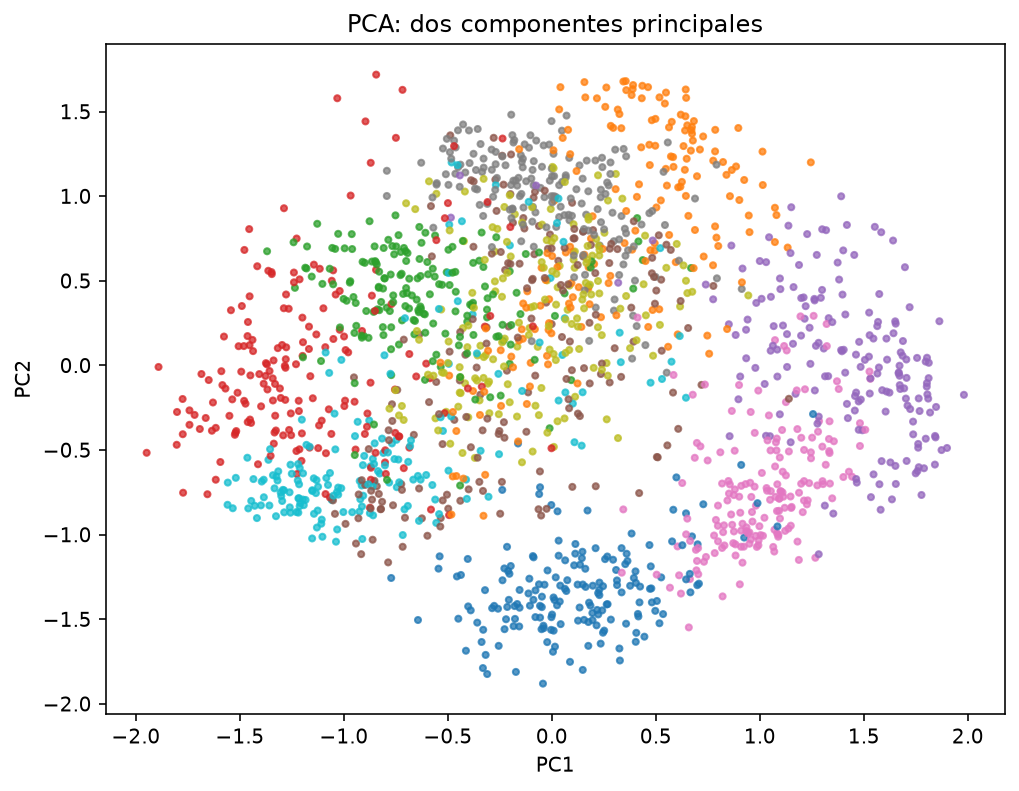

Los ejes son puntuaciones de componentes principales: proyecciones sobre direcciones ortonormales, con unidades derivadas del escalado de entrada. Sus varianzas corresponden a los autovalores. La superposición de clases en dos componentes no demuestra que todo método lineal falle ni que la información se haya perdido en todas las componentes restantes.

#### 2. Panel t-SNE

[Las mismas observaciones con PCA y t-SNE de perplejidad 30.](https://leonctfhtb.github.io/NLP-ASR-ML-DL-2026/assets/mla/laboratorios/clase-04-celda-94-1.html)

Los colores permiten inspeccionar vecindades y mezclas de clases después del ajuste. Pueden aparecer subgrupos y puntos ambiguos; no se exige exactamente una isla por dígito. Los ejes no tienen un significado de característica original y las separaciones entre islas no constituyen una métrica calibrada del espacio de entrada.



*Fig. 4.35. La disposición de una clase no garantiza una interpretación morfológica única.*

### **CELDA 6: Grilla Multifacética de Perplejidad y Curva de Pérdida KL (Seaborn & Matplotlib)**

In [6]:
# ==============================================================================
# CELDA 6: Inspección Estática de Perplejidades y Pérdida KL (Wattenberg et al.)
# ==============================================================================

fig_grid, axes_array = plt.subplots(2, 3, figsize=(18, 11))
axes_flat = axes_array.flatten()

# Graficación de las 5 proyecciones de t-SNE
for subplot_idx, perplexity_val in enumerate(perplexity_candidates):
    current_ax = axes_flat[subplot_idx]
    current_embedding = tsne_results[perplexity_val]["embedding"]
    current_kl = tsne_results[perplexity_val]["kl_divergence"]

    scatter_plot = current_ax.scatter(
        current_embedding[:, 0],
        current_embedding[:, 1],
        c=labels_vector,
        cmap="tab10",
        alpha=0.75,
        s=18,
        edgecolors="none"
    )

    current_ax.set_title(
        f"Perplejidad = {perplexity_val}\nDivergencia KL: {current_kl:.3f}",
        fontsize=12,
        fontweight="bold"
    )
    current_ax.set_xlabel("t-SNE Dim 1", fontsize=10)
    current_ax.set_ylabel("t-SNE Dim 2", fontsize=10)
    current_ax.grid(True, linestyle="--", alpha=0.3)

# Subplot 6: Costos finales de problemas distintos; no comparar como una sola pérdida.
kl_axis = axes_flat[5]
kl_divergences = [tsne_results[p]["kl_divergence"] for p in perplexity_candidates]

kl_axis.plot(
    perplexity_candidates,
    kl_divergences,
    marker="o",
    color="#E63946",
    linewidth=2.5,
    markersize=8
)
kl_axis.set_title("KL final por perplejidad (objetivos distintos)", fontsize=12, fontweight="bold")
kl_axis.set_xlabel("Valor de Perplejidad (k vecinos efectivos)", fontsize=10)
kl_axis.set_ylabel("Divergencia de Kullback-Leibler", fontsize=10)
kl_axis.grid(True, linestyle="--", alpha=0.5)

plt.suptitle(
    "Impacto Geométrico del Hiperparámetro de Perplejidad en t-SNE (Dataset Digits)",
    fontsize=15,
    fontweight="bold",
    y=0.99
)
plt.tight_layout()
plt.show()

#### A. Perplejidad 2

La primera proyección explora una escala de vecindad muy local. Puede generar grupos pequeños o filamentos cuya estabilidad debe contrastarse. Los puntos siguen teniendo afinidades con más de dos muestras en la formulación exacta; «dos vecinos efectivos» es una descripción entrópica.

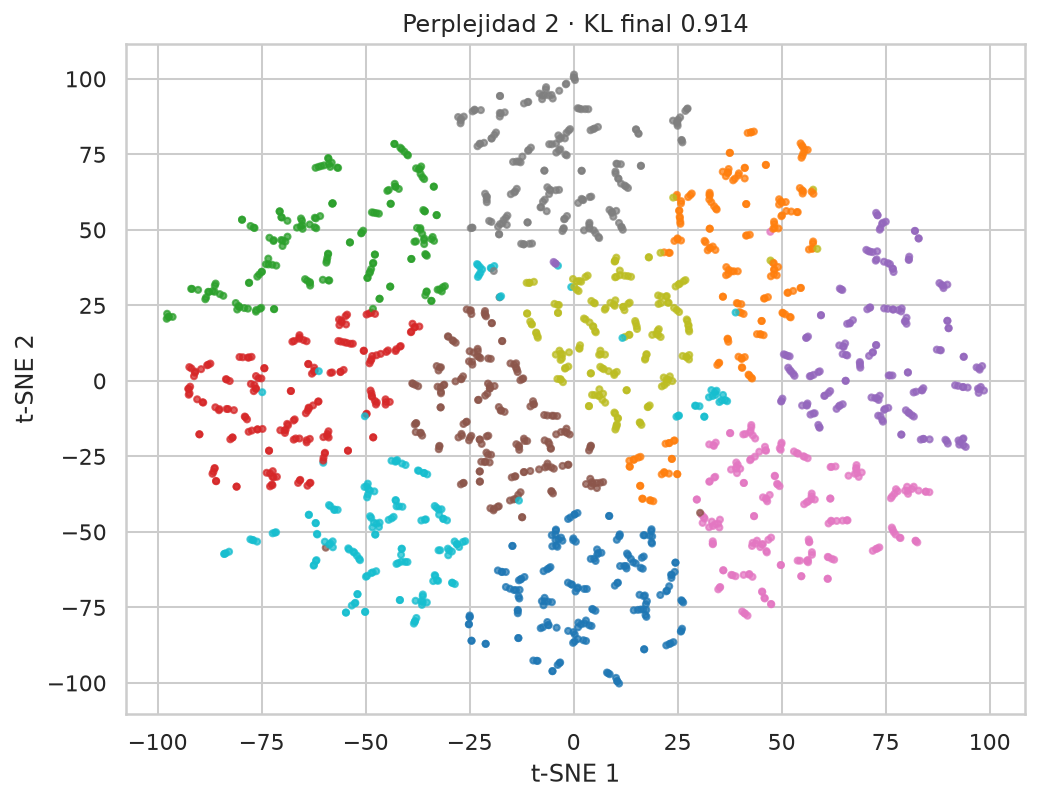

**Perplejidad 10.** Amplía la escala de comparación respecto de 2. Los cambios de forma, subgrupos o mezcla se describen a partir de esta ejecución, sin deducir automáticamente que cada isla es una clase real.

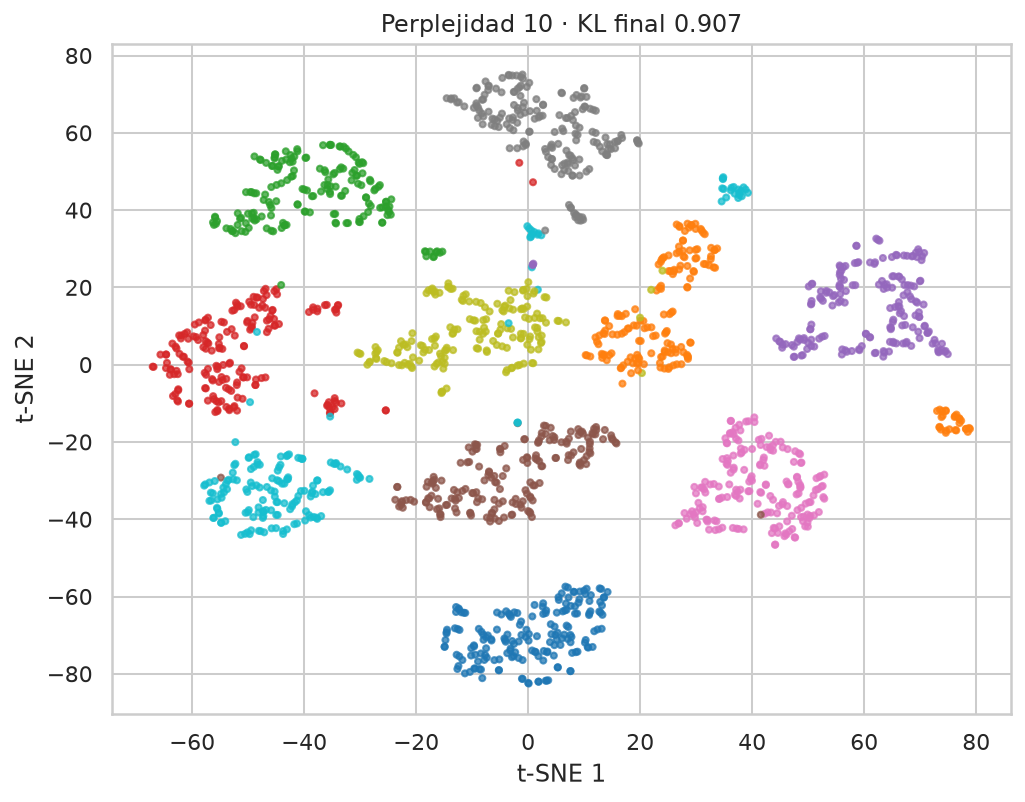

**Perplejidades 30 y 50.** Ofrecen otras dos escalas de análisis. Se revisan continuidad local, mezclas y estabilidad entre ejecuciones. El rango 5–50 es habitual como punto de partida, sin una garantía de balance óptimo.

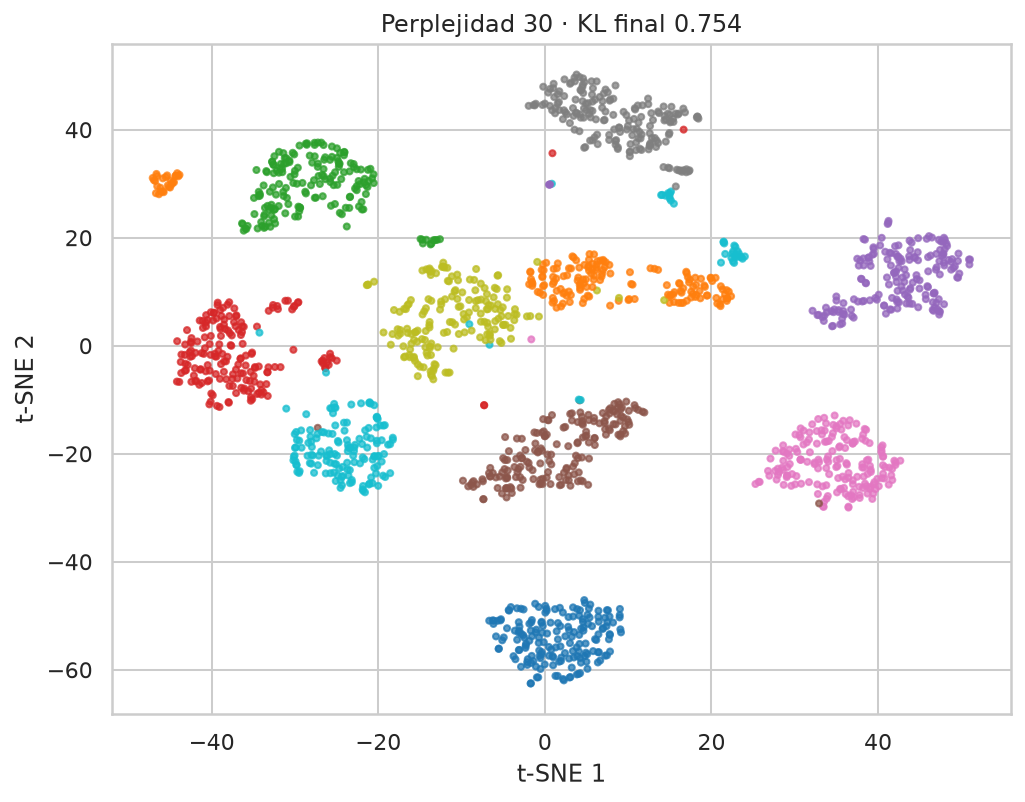

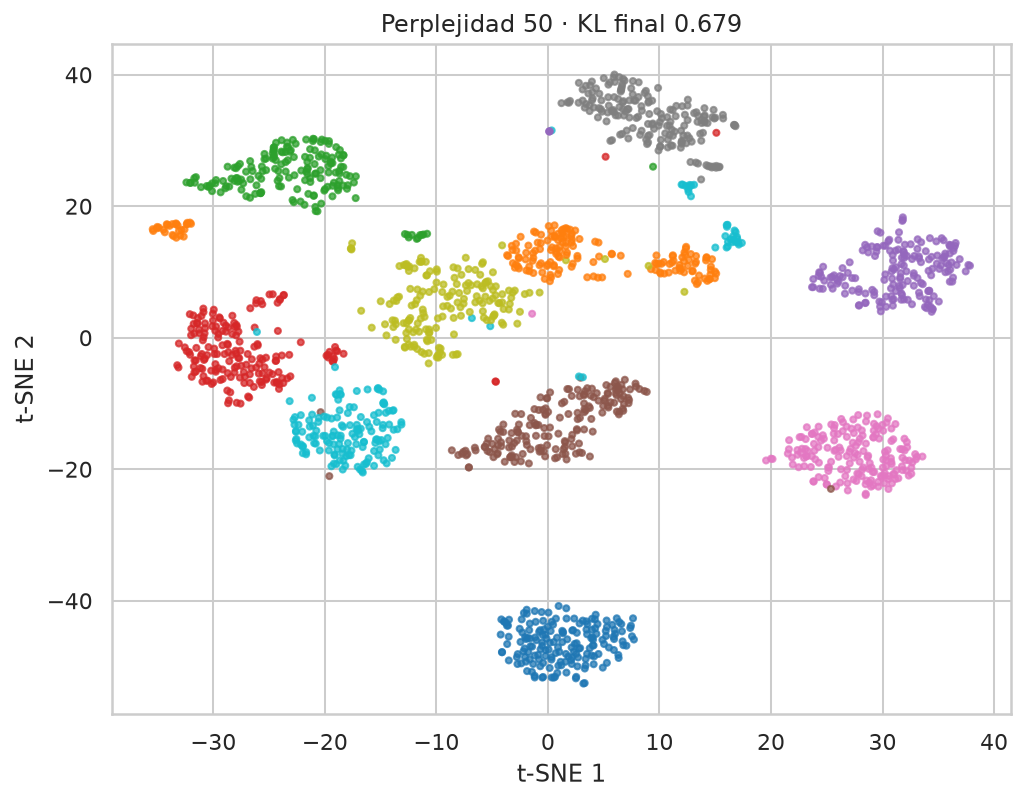

**Perplejidad 100.** Considera una escala de vecindad más amplia. Puede cambiar compacidad y disposición relativa; no implica necesariamente un único cúmulo ni un error de ajuste. Su utilidad depende de la estructura que se quiera investigar.

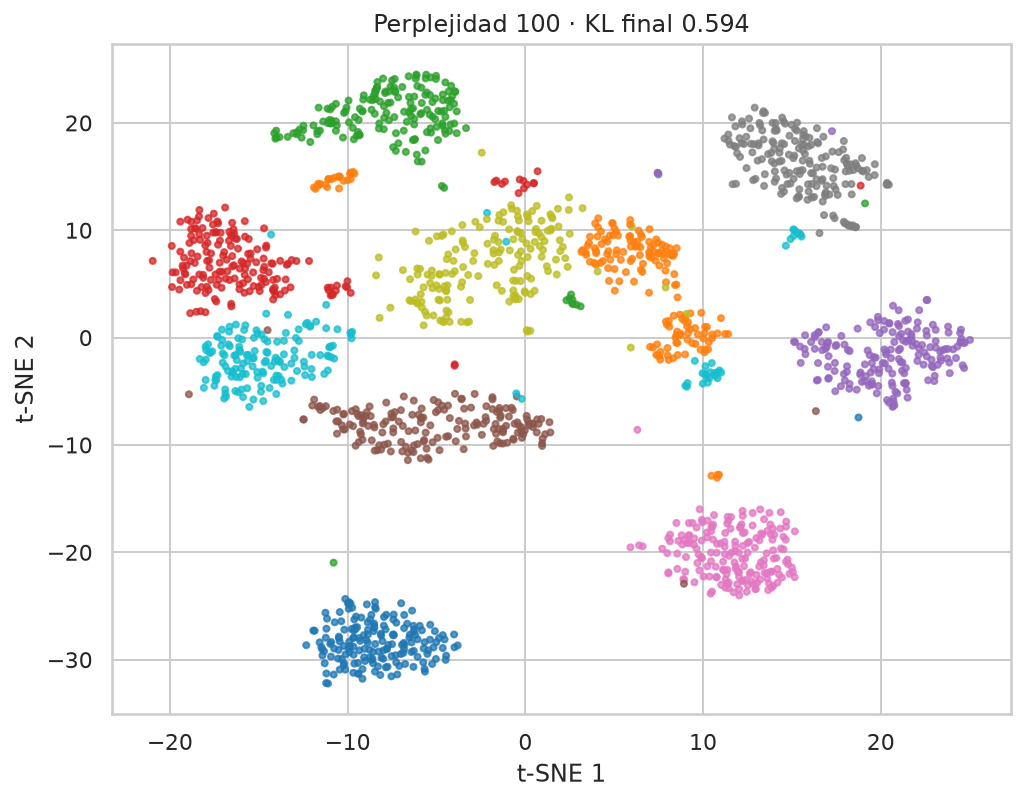

#### **B. Deconstrucción del Subplot 6: La Curva KL vs. Perplejidad**

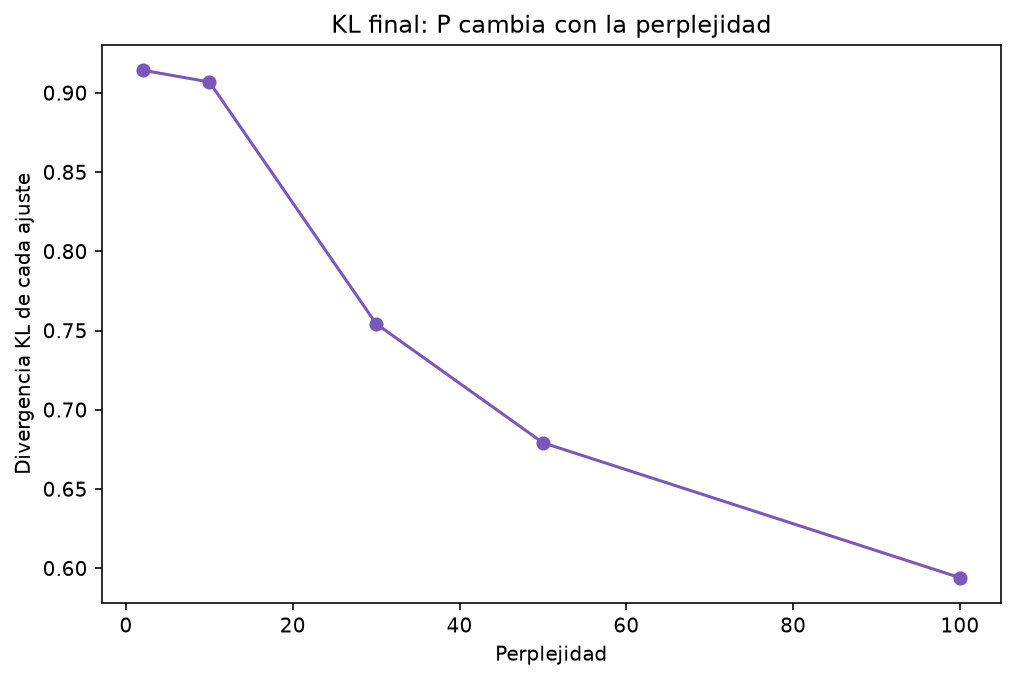

La curva KL frente a perplejidad registra costos finales de problemas distintos, porque cambia la matriz de afinidades $P$. No es una curva de convergencia temporal ni tiene que ser monótona. No se selecciona el mejor mapa eligiendo su mínimo. La evaluación debe combinar el objetivo del estudio, estabilidad y medidas de preservación de vecindad cuando sean pertinentes.

## Referencias y lecturas

- [Visualizing Data using t-SNE · van der Maaten y Hinton, 2008](https://www.jmlr.org/papers/volume9/vandermaaten08a/vandermaaten08a.pdf)
- [TSNE · scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html)
- [load_digits · scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)

Referencias del material de origen: [tesis de grado](https://drive.google.com/file/d/1fxbhCJ6f9nTZXvzaqboVLrMFQE1AlXZv/view) y [Dive into Deep Learning](https://d2l.ai/). Los textos y figuras de terceros conservan sus créditos y condiciones.